# Forecasting ERCOT load, and what Houston hub prices do with it

Tanner Allred. A day-ahead study on public ERCOT load and settlement prices, with Open-Meteo weather.

The desk question is narrow. Standing at the start of an operating day, with yesterday's load and yesterday's weather in hand, how close can a model get to tomorrow's hourly system load? And does that same information say anything useful about the Houston day-ahead price, including on the hours everyone still talks about from February 2021?

The short version, computed in the cells below rather than typed in by hand:

- Load has a U-shape in temperature. Cooling degrees, base 65°F, track it more tightly than raw temperature.
- A 24-hour seasonal naive load forecast is already inside about 4% MAPE on the 2024–2025 test windows. Gradient boosting beats it by a modest amount. SARIMAX does not, on the pooled hours.
- Knowing the actual temperature, as a perfect weather forecast would, is worth more than the choice between SARIMAX and a tree.
- Houston day-ahead prices on ordinary weeks are mostly yesterday's price. Load and weather do not beat persistence.
- Winter Storm Uri is the exception that makes the point. Load peaked near 70 GW and then fell, while the Houston real-time price stayed near the cap and printed $9,160.85/MWh on an hour when load was about 43 GW. The sample's highest load hour, 85.5 GW on an August 2023 afternoon, was expensive and still far short of that.

## Setup

The processed cache lives in `data/processed/`. `scripts/download_data.py` rebuilds it from ERCOT and Open-Meteo if you want a fresh pull. Nothing in that script needs an API key.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "ercot_forecast").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from ercot_forecast.config import FIGURES, FOLDS, LOAD_GBM_LAGGED, SARIMAX_EXOG
from ercot_forecast.download import load_hourly_frame, load_zone_weights
from ercot_forecast.features import build_features, cooling_degrees, heating_degrees
from ercot_forecast.pipeline import run_analysis

pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
pd.set_option("display.max_columns", 40)
print("Project root:", ROOT)

Project root: /workspace


## The hourly frame

Native load is ERCOT's archive by weather zone. Prices are the historical DAM and RTM hub files. Real-time prices are collapsed from the 15-minute settlement intervals to an hourly mean, and I keep the hourly maximum so a single spike inside the hour is still visible. Weather is the Open-Meteo archive at one city in each zone. The join key is the start of the hour in UTC, after translating ERCOT's hour-ending clock, including the repeated hour on the November fallback.

In [2]:
hourly = load_hourly_frame()
weights = load_zone_weights()
print(f"{len(hourly):,} hours")
print(hourly["interval_start"].iloc[0], "→", hourly["interval_start"].iloc[-1])
print("Null share, selected columns:")
print(hourly[["load_ercot", "dam_hb_houston", "rtm_hb_houston_max", "temp_c_coast"]].isna().mean().round(6))
print("Zone weights (share of average load):")
print(weights.sort_values(ascending=False).round(3))

43,824 hours
2021-01-01 06:00:00+00:00 → 2026-01-01 05:00:00+00:00
Null share, selected columns:
load_ercot           0.00
dam_hb_houston       0.00
rtm_hb_houston_max   0.00
temp_c_coast         0.00
dtype: float64
Zone weights (share of average load):
ncent   0.29
coast   0.27
scent   0.16
fwest   0.11
south   0.08
east    0.03
west    0.03
north   0.03
dtype: float64


## Features

Cooling and heating degrees use a 65°F base and are left as hourly degrees. The weighted temperature uses the zone shares above, which are constants computed from the whole sample, so they do not leak the hour being forecast. Lags are shifts on the regular UTC index. A day-ahead origin is allowed to see lag 24 and longer, not the current hour.

In [3]:
featured = build_features(hourly, weights)
print("80°F is", float(cooling_degrees(80)), "cooling degrees and", float(heating_degrees(80)), "heating degrees")
print("Day-ahead load features:")
print(LOAD_GBM_LAGGED)
print("SARIMAX exogenous columns, also known at a day-ahead origin:", SARIMAX_EXOG)
featured[["interval_start", "load_ercot", "temp_f_weighted", "cdd_weighted", "hdd_weighted", "load_ercot_lag_24"]].head(3)

80°F is 15.0 cooling degrees and 0.0 heating degrees
Day-ahead load features:
['load_ercot_lag_24', 'load_ercot_lag_48', 'load_ercot_lag_168', 'load_ercot_roll168_lag_24', 'temp_f_weighted_lag_24', 'temp_f_coast_lag_24', 'temp_f_ncent_lag_24', 'temp_f_scent_lag_24', 'cdd_weighted_lag_24', 'hdd_weighted_lag_24', 'hour', 'dow', 'month', 'is_weekend', 'is_holiday']
SARIMAX exogenous columns, also known at a day-ahead origin: ['temp_f_weighted_lag_24', 'is_weekend']


,interval_start,load_ercot,temp_f_weighted,cdd_weighted,hdd_weighted,load_ercot_lag_24
0,2021-01-01 06:00:00+00:00,"43,719.85",39.94,0.00,25.06,NaN
1,2021-01-01 07:00:00+00:00,"43,321.05",39.02,0.00,25.98,NaN
2,2021-01-01 08:00:00+00:00,"43,063.07",38.95,0.00,26.05,NaN


## Models and the test windows

Five windows, each 14 days, all after a June 2024 validation slice used only to pick the boosting hyperparameters and the SARIMAX order:

- July 15–28, 2024
- December 9–22, 2024
- April 7–20, 2025
- August 4–17, 2025
- October 13–26, 2025

The baselines are seasonal naive forecasts at 24 and 168 hours. SARIMAX is refit on the trailing six weeks before each window and then steps forward one Central day at a time. The trees train on every earlier hour. Later windows are allowed to see earlier test periods. That is an expanding evaluation.

The realized-weather load model, and the realized-load price model, are diagnostics. They answer "what if the weather forecast or the load forecast were perfect?" They are not day-ahead scores.

In [4]:
for fold in FOLDS:
    print(f"{fold['name']}: {fold['test_start']} to {fold['test_end']} (end exclusive)")
summary = run_analysis(save=True)
scorecard = summary["metrics"].copy()
scorecard["mae"] = scorecard["mae"].round(2)
scorecard["rmse"] = scorecard["rmse"].round(2)
scorecard["mape"] = scorecard["mape"].round(2)
scorecard["skill_vs_naive_24"] = scorecard["skill_vs_naive_24"].round(3)
scorecard[["target", "model", "info_set", "n", "mae", "rmse", "mape", "skill_vs_naive_24"]]

summer_2024: 2024-07-15 to 2024-07-29 (end exclusive)
winter_2024: 2024-12-09 to 2024-12-23 (end exclusive)
spring_2025: 2025-04-07 to 2025-04-21 (end exclusive)
summer_2025: 2025-08-04 to 2025-08-18 (end exclusive)
fall_2025: 2025-10-13 to 2025-10-27 (end exclusive)


,target,model,info_set,n,mae,rmse,mape,skill_vs_naive_24
0,load_ercot,seasonal_naive_24,day_ahead,1680,"2,219.20","2,924.03",4.01,0.00
1,load_ercot,seasonal_naive_168,day_ahead,1680,"3,824.57","5,141.97",6.91,-0.72
2,load_ercot,gbm_lagged_weather,day_ahead,1680,"2,112.61","2,824.18",3.83,0.05
3,load_ercot,gbm_realized_weather,realized_weather,1680,"1,906.05","2,348.61",3.38,0.14
4,load_ercot,sarimax,day_ahead,1680,"2,404.69","3,260.93",4.38,-0.08
5,dam_hb_houston,seasonal_naive_24,day_ahead,1680,7.72,14.43,24.63,0.00
6,dam_hb_houston,seasonal_naive_168,day_ahead,1680,11.84,25.00,41.79,-0.54
7,dam_hb_houston,ols_lagged,day_ahead,1680,19.96,26.34,80.56,-1.59
8,dam_hb_houston,gbm_lagged_weather,day_ahead,1680,8.88,16.35,28.97,-0.15
9,dam_hb_houston,gbm_realized_load_weather,realized_load_and_weather,1680,8.37,14.96,28.22,-0.09


## What the scorecard says

Read the table from the cell above. On load, the 24-hour naive is the bar. Boosting clears it on the pooled 1,680 hours and misses it in December 2024. SARIMAX wins July 2024 and loses the cold window by a wide margin. Realized temperature helps most in the shoulder.

On the Houston day-ahead price, yesterday's price wins the pooled MAE. The tree wins three of the five windows and loses both summers by enough to give the naive forecast the pooled score. OLS, which is the right statistical tool when you want a coefficient and the wrong one when the series is a spike process, is far behind. Even the oracle that sees same-hour load and weather does not beat persistence on these ordinary weeks.

In [5]:
by_fold = pd.DataFrame(summary["metrics_by_fold"])
load_folds = by_fold.loc[
    (by_fold["target"] == "load_ercot")
    & (by_fold["model"].isin(["seasonal_naive_24", "sarimax", "gbm_lagged_weather", "gbm_realized_weather"]))
]
load_mae = load_folds.pivot(index="fold", columns="model", values="mae").round(0)
print("Load MAE (MW) by window")
display(load_mae)

prices = summary["prices"]
uri = prices["uri"]
peak = prices["peak_load_hour"]
peak_price = prices["peak_rtm_hour"]
week = prices["peak_load_week"]
print(
    f"Uri window {uri['start']} to {uri['end']} (end exclusive): "
    f"load peaked at {uri['load_max_mw']:.0f} MW on {uri['load_max_at_ct']}. "
    f"Houston real-time peaked at ${uri['rtm_hb_houston_max']:,.2f}/MWh on {uri['rtm_max_at_ct']}, "
    f"when load was {peak_price['load_mw']:.0f} MW and the load-weighted temperature was {peak_price['temp_f_weighted']:.1f}°F."
)
print(
    f"Highest load hour: {peak['at_ct']}, {peak['load_mw']:.0f} MW, "
    f"Houston {peak['temp_f_coast']:.1f}°F, DAM ${peak['dam_hb_houston']:,.2f}/MWh, "
    f"RTM max ${peak['rtm_hb_houston_max']:,.2f}/MWh."
)
print(
    f"Highest-load week {week['start_ct']} to {week['end_ct']}: "
    f"mean load {week['load_mean_mw']:.0f} MW, mean DAM ${week['dam_hb_houston_mean']:,.2f}/MWh, "
    f"RTM max ${week['rtm_hb_houston_max']:,.2f}/MWh."
)
capped = prices["ols"]["dam_below_200"]
print(
    f"OLS on DAM prices under $200/MWh: n={capped['n']:,}, R²={capped['r2']:.2f}, "
    f"CDD ${capped['coefs']['cdd_weighted']['coef']:.2f}/MWh per degree, "
    f"HDD ${capped['coefs']['hdd_weighted']['coef']:.2f}, "
    f"Far West wind ${capped['coefs']['wind_mph_fwest']['coef']:.2f} per mph."
)

Load MAE (MW) by window


model,gbm_lagged_weather,gbm_realized_weather,sarimax,seasonal_naive_24
fold,,,,
fall_2025,"2,349.00","2,030.00","2,967.00","2,849.00"
spring_2025,"1,845.00",982.00,"1,951.00","2,147.00"
summer_2024,"2,347.00","2,463.00","1,966.00","2,336.00"
summer_2025,"1,754.00","2,248.00","2,073.00","1,930.00"
winter_2024,"2,268.00","1,807.00","3,068.00","1,834.00"


Uri window 2021-02-13 to 2021-02-20 (end exclusive): load peaked at 69692 MW on 2021-02-14T19:00:00-06:00. Houston real-time peaked at $9,160.85/MWh on 2021-02-17T04:00:00-06:00, when load was 43135 MW and the load-weighted temperature was 26.1°F.
Highest load hour: 2023-08-10T17:00:00-05:00, 85464 MW, Houston 100.2°F, DAM $1,667.83/MWh, RTM max $4,089.36/MWh.
Highest-load week 2023-08-07T18:00:00-05:00 to 2023-08-14T17:00:00-05:00: mean load 69985 MW, mean DAM $160.81/MWh, RTM max $4,720.65/MWh.
OLS on DAM prices under $200/MWh: n=42,901, R²=0.28, CDD $1.68/MWh per degree, HDD $0.92, Far West wind $-0.65 per mph.


## Charts

The same figures are written to `reports/figures/` for the README. The Uri panel is the one to sit with: load peaks on the evening of February 14 and is back in the mid-40s GW while the price is still on the cap. The August 2023 panel is a summer peak that actually looks like a load story, with the high prices stacked on the hottest afternoons and gone overnight.

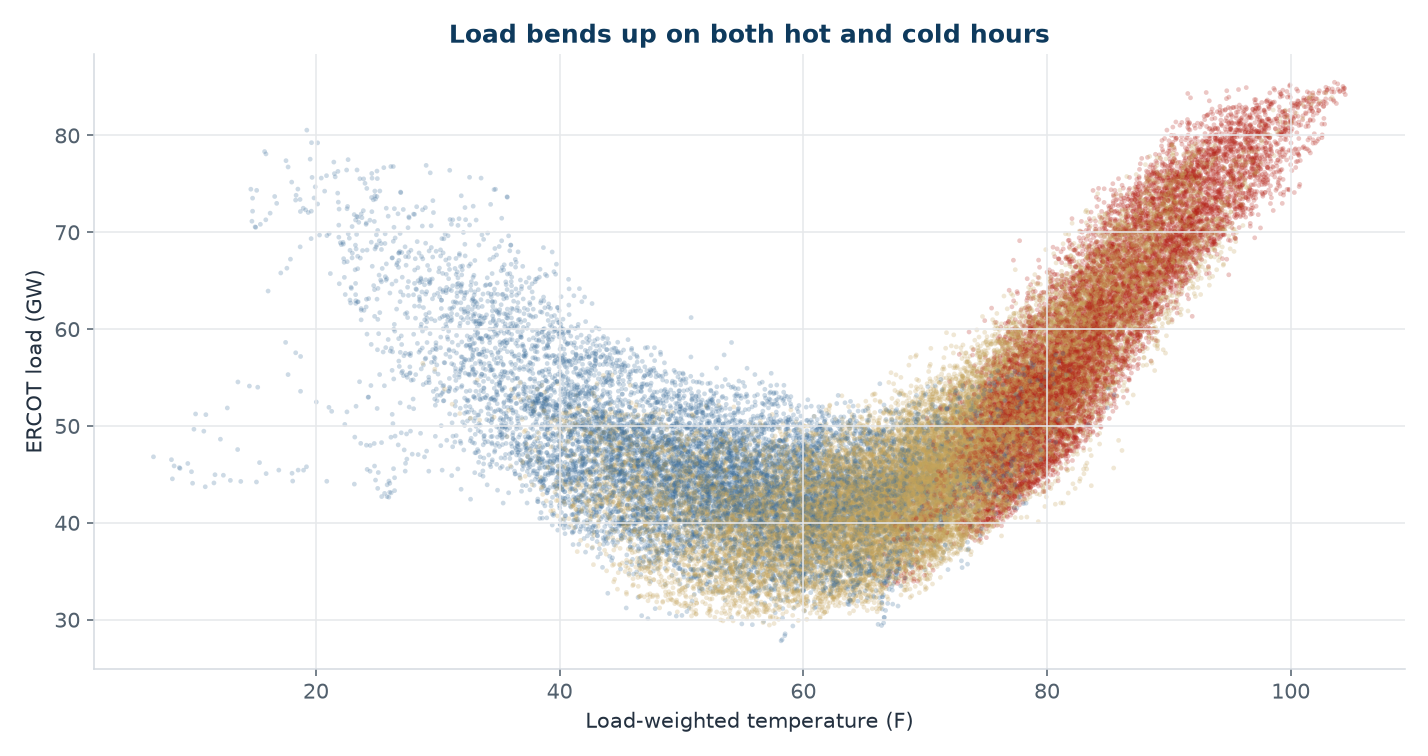

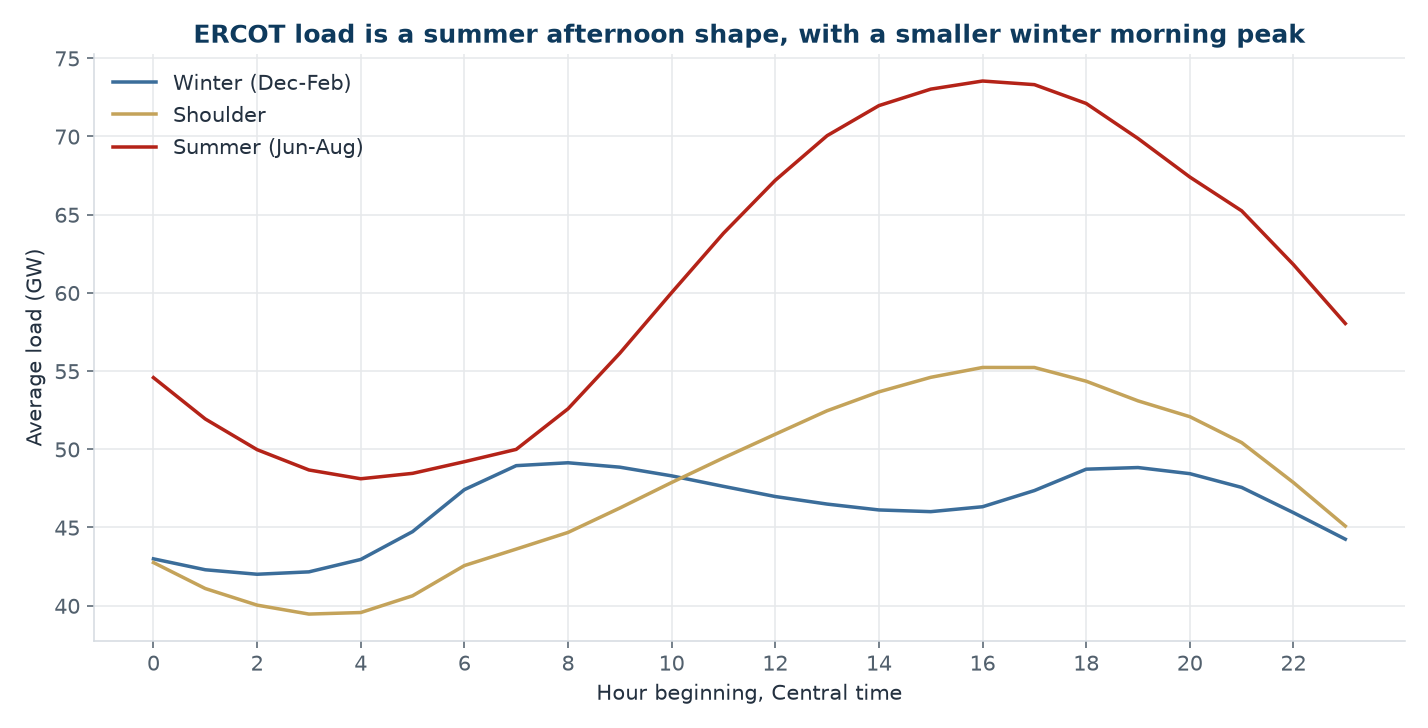

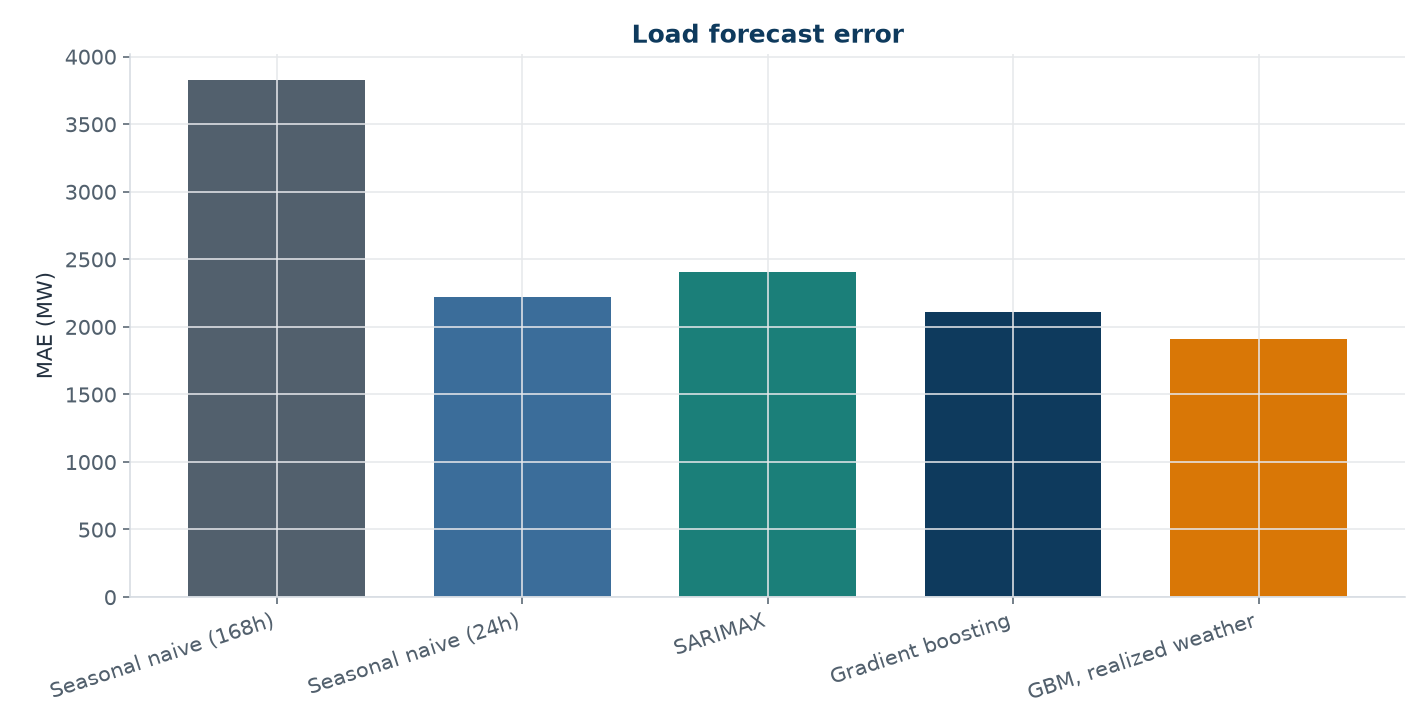

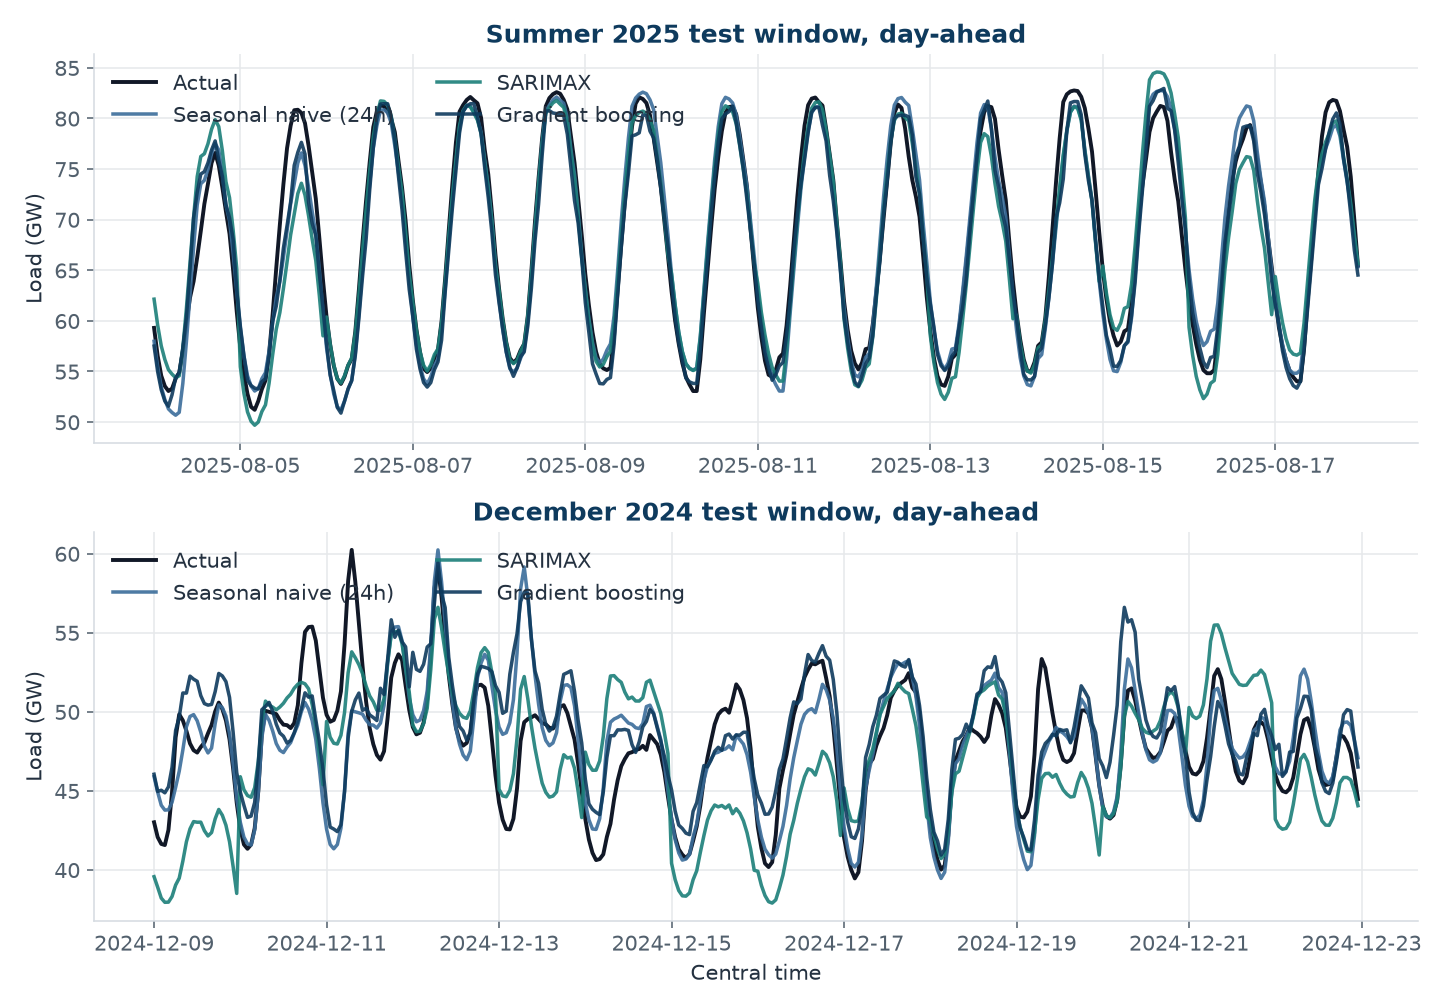

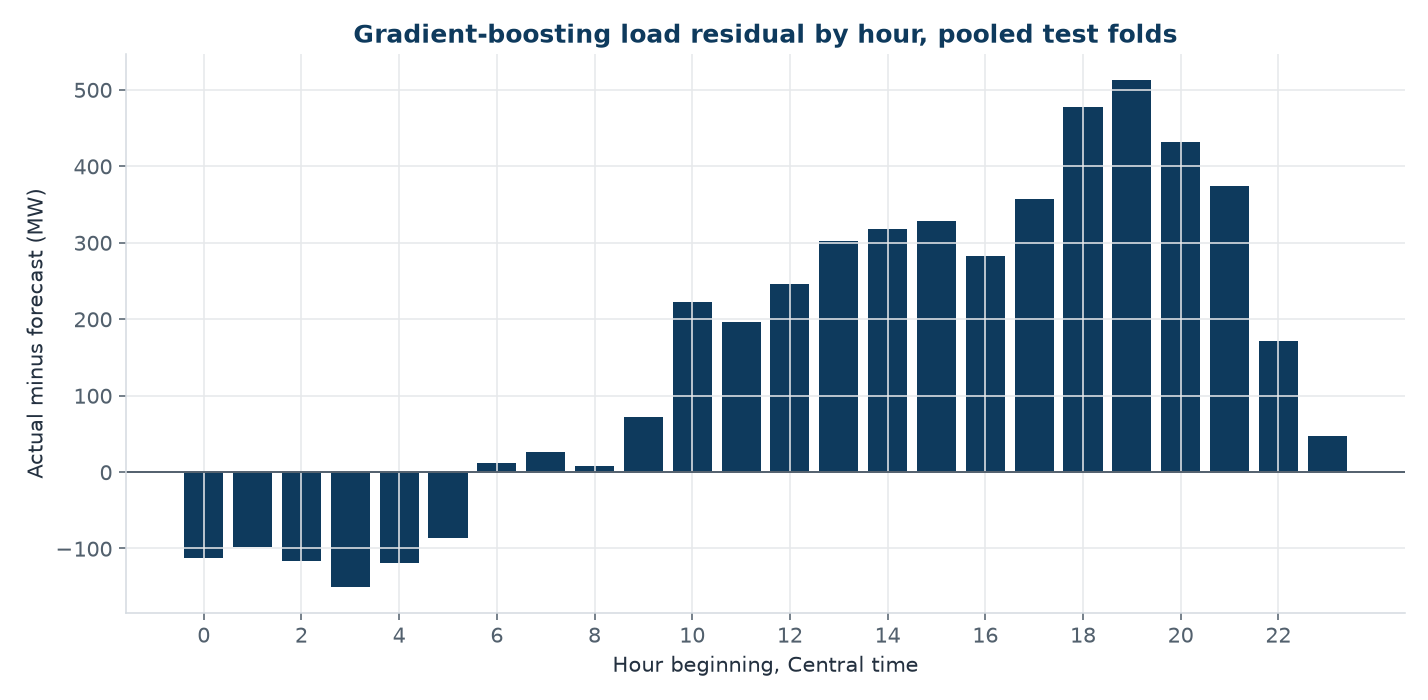

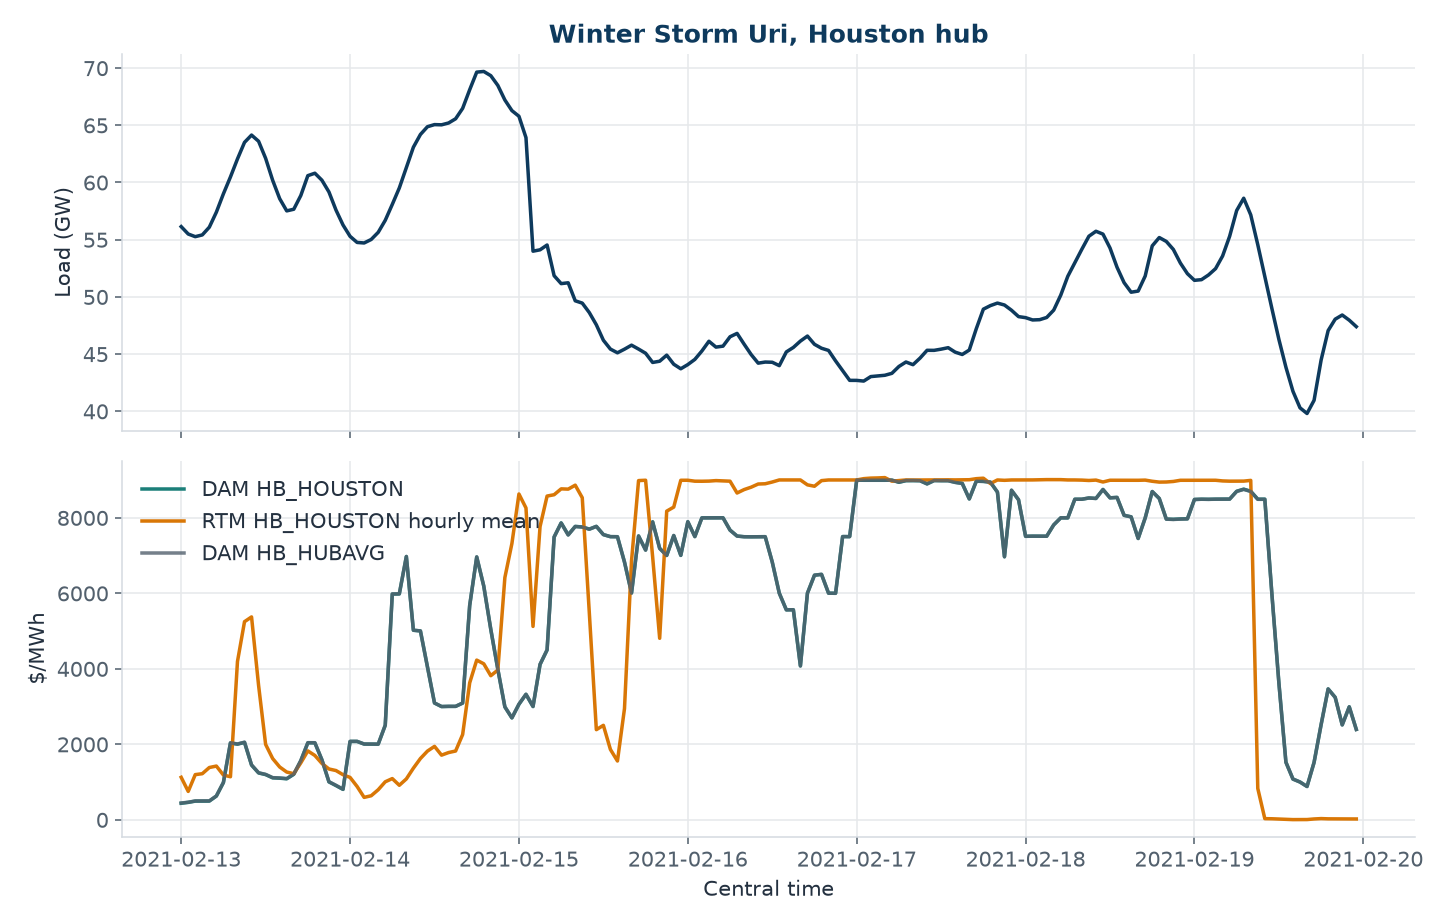

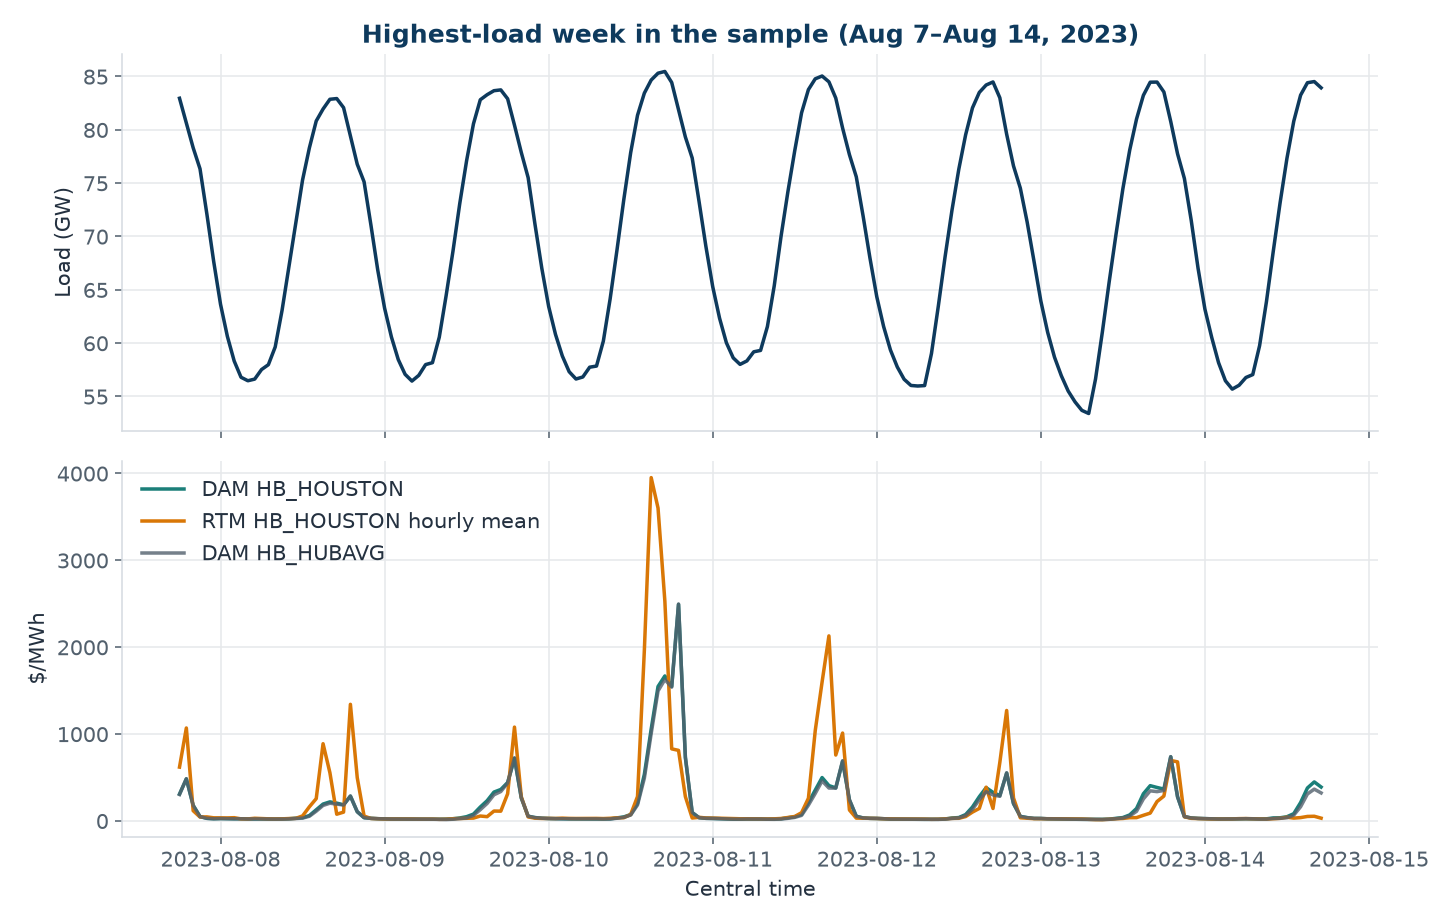

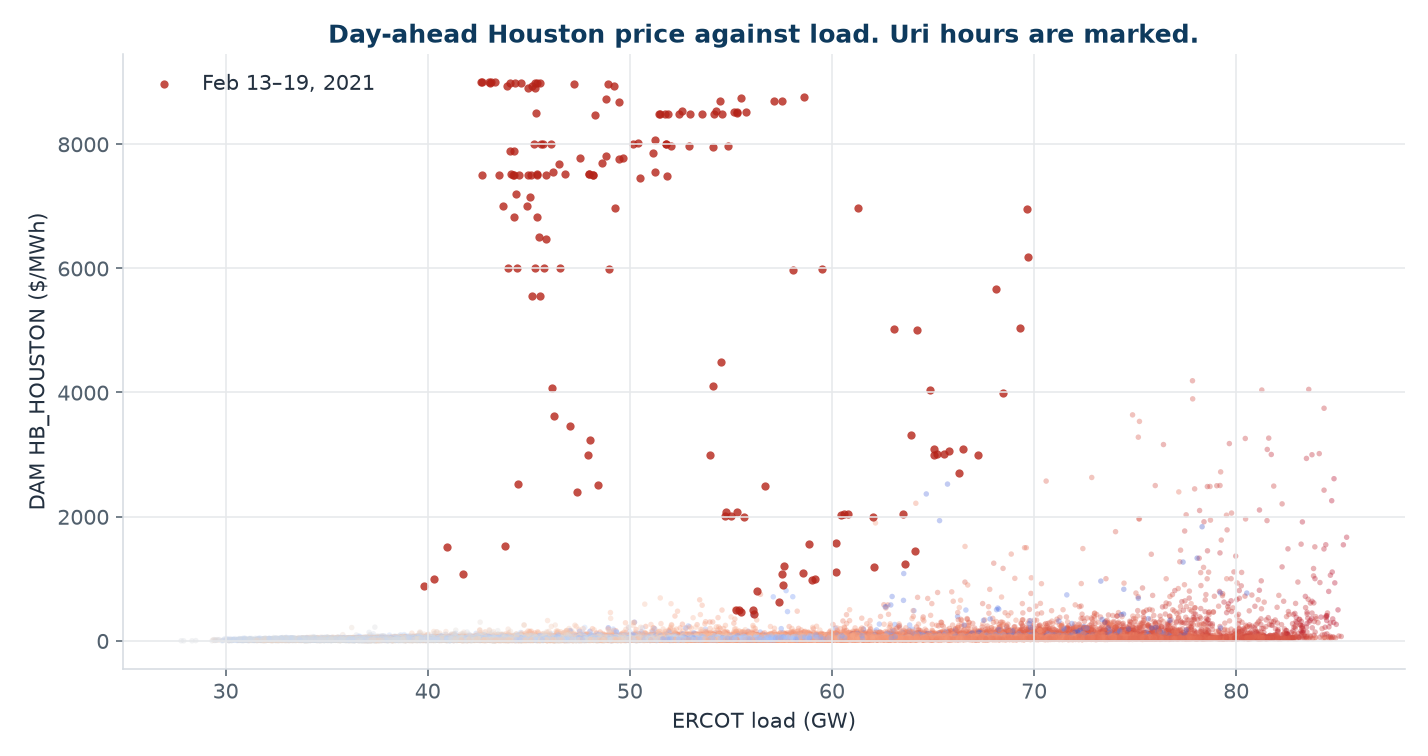

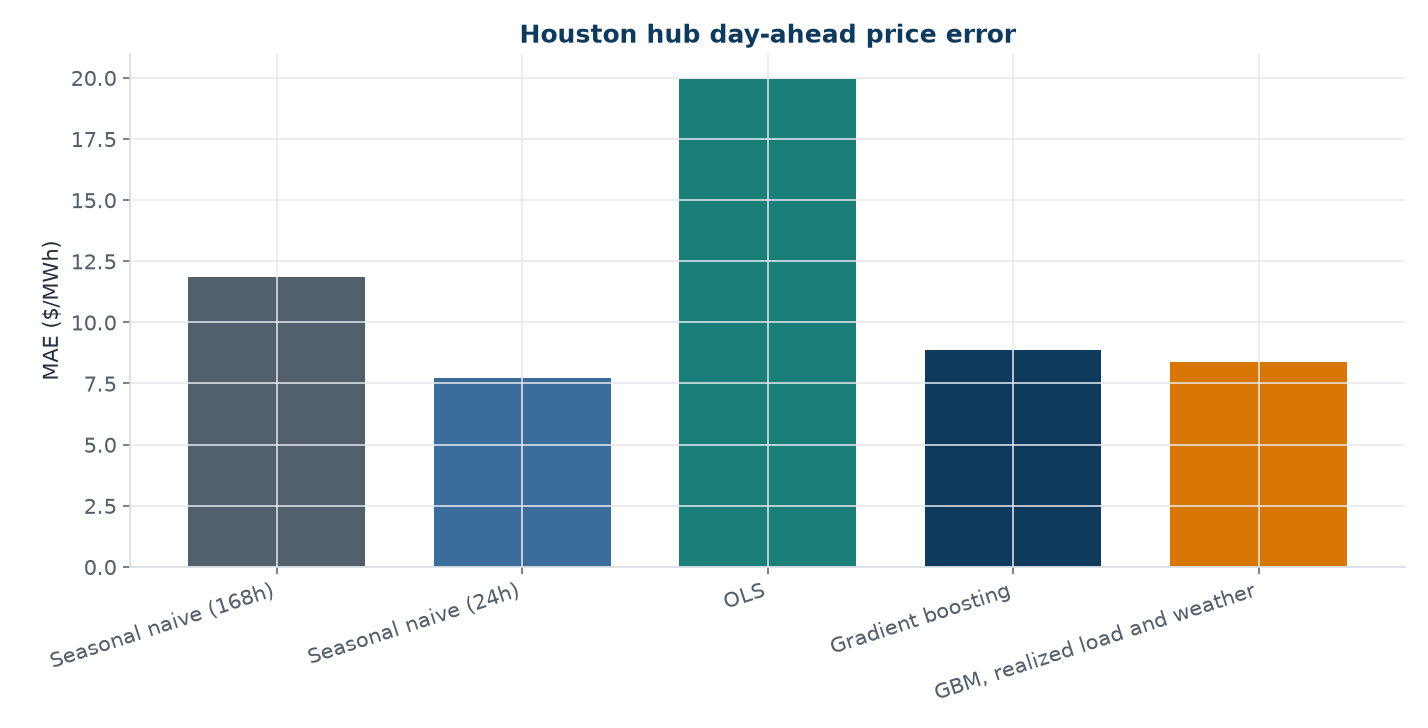

In [6]:
for name in [
    "load_vs_temperature.png",
    "load_hourly_profile.png",
    "load_metrics.png",
    "load_forecast_overlay.png",
    "load_residual_by_hour.png",
    "uri_february_2021.png",
    "peak_load_week.png",
    "price_vs_load.png",
    "price_metrics.png",
]:
    display(Image(filename=str(FIGURES / name)))

## What I would hand a trader

I would hand over the load forecast as a day-ahead baseline with the December miss written on it, and I would not hand over the price model as a mark. The price work is a screen: summer afternoons at high load have a fatter right tail, Far West wind leans the ordinary price down in the capped regression, and a week like February 13–19, 2021 is not on the load curve at all. Pricing that week needs outages and fuel, which this dataset does not have.

## Limits

The weather in the operational models is yesterday's weather, not a forecast vendor. The realized-weather row is the upper bound on what a good forecast could add, not a backtest of one. SARIMAX is a short local model, refit on six weeks, because a single hourly specification across five years is a different project and a much slower one. Test windows are two weeks each, so a single cold front moves the score. The price regression is an association, with robust standard errors, not a causal offer-stack model.

## About

I am Tanner Allred, in Houston. M.S. in Data Analytics, B.S. in Economics, and the last few years spent on annuity and pension-risk-transfer analytics: reconciling policy data, forecasting cash flows, and turning manual reports into Python. I am looking at energy trading, scheduling, and analytics roles. Other work is at [github.com/tannerman1227](https://github.com/tannerman1227).